# Análise Exploratória — AdventureWorks

**Pergunta que esta análise responde:** o que está sendo vendido, onde e em qual canal?

**Ferramentas:** Python, Pandas, Matplotlib e Seaborn.

**Etapas:** 1) Importar os dados · 2) Limpeza · 3) Juntar as tabelas · 4) Análise exploratória · 5) Conclusões

## 1. Importar os dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mostrar números sem notação científica
pd.options.display.float_format = "{:,.0f}".format

# A planilha está na pasta acima (raiz do repositório)
arquivo = "../AdventureWorks_Sales.xlsx"

vendas = pd.read_excel(arquivo, sheet_name="Sales_data")
pedidos = pd.read_excel(arquivo, sheet_name="Sales Order_data")
produtos = pd.read_excel(arquivo, sheet_name="Product_data")
clientes = pd.read_excel(arquivo, sheet_name="Customer_data")
territorios = pd.read_excel(arquivo, sheet_name="Sales Territory_data")

vendas.head()

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount
0,43659001,676,-1,349,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025"
1,43659002,676,-1,350,20170702,20170712,"20,170,709",5,3,"2,025","6,075",0,"1,898","5,694","6,075"
2,43659003,676,-1,351,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025"
3,43659004,676,-1,344,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040"
4,43659005,676,-1,345,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040"


## 2. Limpeza dos dados

In [2]:
# Tem valores vazios? Tem linhas repetidas?
print("Valores vazios por coluna:")
print(vendas.isnull().sum())
print()
print("Linhas repetidas:", vendas.duplicated().sum())

Valores vazios por coluna:
SalesOrderLineKey             0
ResellerKey                   0
CustomerKey                   0
ProductKey                    0
OrderDateKey                  0
DueDateKey                    0
ShipDateKey                2113
SalesTerritoryKey             0
Order Quantity                0
Unit Price                    0
Extended Amount               0
Unit Price Discount Pct       0
Product Standard Cost         0
Total Product Cost            0
Sales Amount                  0
dtype: int64

Linhas repetidas: 0


Só a coluna `ShipDateKey` (data de envio) tem valores vazios: são pedidos que ainda não foram enviados. Não vamos usar essa coluna, então não precisa corrigir. Também não há linhas repetidas.

Agora vamos transformar a data do pedido (que está como número, tipo `20170702`) em data de verdade.

In [3]:
vendas["Data"] = pd.to_datetime(vendas["OrderDateKey"].astype(str), format="%Y%m%d")
vendas["Ano"] = vendas["Data"].dt.year

print("A base vai de", vendas["Data"].min().date(), "até", vendas["Data"].max().date())

A base vai de 2017-07-01 até 2020-06-15


## 3. Juntar as tabelas

Os dados estão separados em várias tabelas. Vamos juntá-las (como um PROCV do Excel) para ter tudo em uma só.

In [4]:
df = vendas.merge(pedidos[["SalesOrderLineKey", "Channel", "Sales Order"]], on="SalesOrderLineKey")
df = df.merge(produtos[["ProductKey", "Category"]], on="ProductKey")
df = df.merge(territorios[["SalesTerritoryKey", "Country"]], on="SalesTerritoryKey")

df.head()

,SalesOrderLineKey,ResellerKey,CustomerKey,ProductKey,OrderDateKey,DueDateKey,ShipDateKey,SalesTerritoryKey,Order Quantity,Unit Price,Extended Amount,Unit Price Discount Pct,Product Standard Cost,Total Product Cost,Sales Amount,Data,Ano,Channel,Sales Order,Category,Country
0,43659001,676,-1,349,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025",2017-07-02,2017,Reseller,SO43659,Bikes,United States
1,43659002,676,-1,350,20170702,20170712,"20,170,709",5,3,"2,025","6,075",0,"1,898","5,694","6,075",2017-07-02,2017,Reseller,SO43659,Bikes,United States
2,43659003,676,-1,351,20170702,20170712,"20,170,709",5,1,"2,025","2,025",0,"1,898","1,898","2,025",2017-07-02,2017,Reseller,SO43659,Bikes,United States
3,43659004,676,-1,344,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040",2017-07-02,2017,Reseller,SO43659,Bikes,United States
4,43659005,676,-1,345,20170702,20170712,"20,170,709",5,1,"2,040","2,040",0,"1,912","1,912","2,040",2017-07-02,2017,Reseller,SO43659,Bikes,United States


## 4. Análise exploratória

### Receita por canal de venda

Channel
Internet   29,358,677
Reseller   80,450,597
Name: Sales Amount, dtype: float64


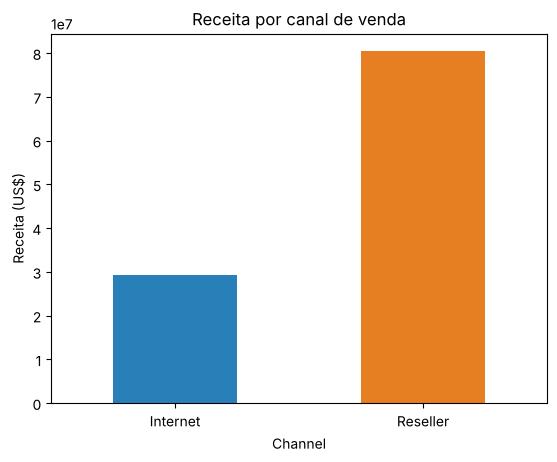

In [5]:
receita_canal = df.groupby("Channel")["Sales Amount"].sum()
print(receita_canal)

receita_canal.plot(kind="bar", color=["#2980b9", "#e67e22"])
plt.title("Receita por canal de venda")
plt.ylabel("Receita (US$)")
plt.xticks(rotation=0)
plt.show()

### Receita por categoria de produto

Category
Accessories    1,272,058
Bikes         94,620,526
Clothing       2,117,613
Components    11,799,077
Name: Sales Amount, dtype: float64


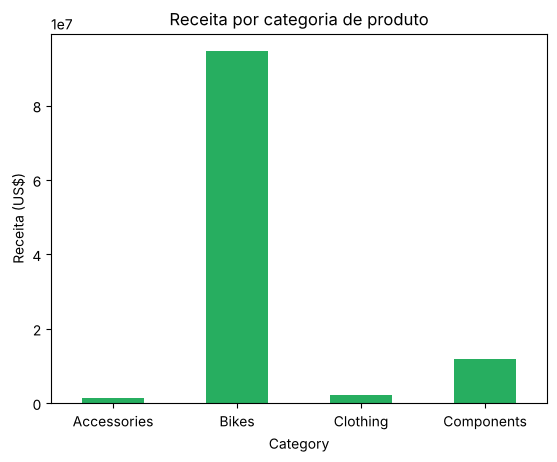

In [6]:
receita_categoria = df.groupby("Category")["Sales Amount"].sum()
print(receita_categoria)

receita_categoria.plot(kind="bar", color="#27ae60")
plt.title("Receita por categoria de produto")
plt.ylabel("Receita (US$)")
plt.xticks(rotation=0)
plt.show()

### Receita por ano

Ano
2017   11,928,556
2018   30,516,892
2019   42,895,110
2020   24,468,717
Name: Sales Amount, dtype: float64


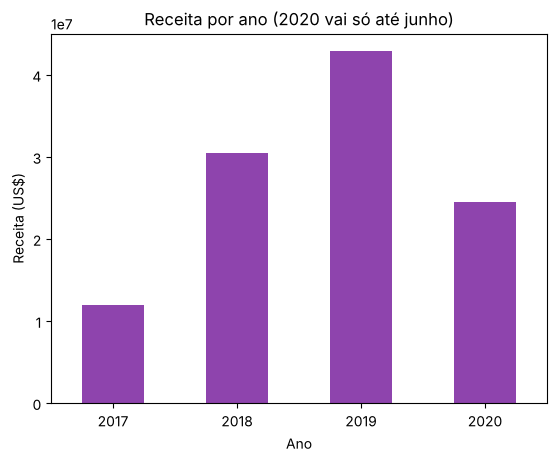

In [7]:
receita_ano = df.groupby("Ano")["Sales Amount"].sum()
print(receita_ano)

receita_ano.plot(kind="bar", color="#8e44ad")
plt.title("Receita por ano (2020 vai só até junho)")
plt.ylabel("Receita (US$)")
plt.xticks(rotation=0)
plt.show()

## 5. Conclusões

- **Canais:** os revendedores vendem mais (cerca de US$ 80,5 milhões) do que a loja online (cerca de US$ 29,4 milhões).
- **Produtos:** *Bikes* representam cerca de 86% de toda a receita.
- **Evolução:** a receita cresceu de 2017 a 2019 (2020 só vai até junho).

**Próximo passo:** entender o comportamento dos clientes e por que alguns deixam de comprar (veja a análise `02_clientes_perdidos`).